# Sentiment Analysis Pipeline: TF-IDF + Naive Bayes / Logistic Regression

**Pipeline:** load reviews → clean (lowercase, strip HTML/punctuation) → tokenize → remove stopwords → lemmatize → `TfidfVectorizer(max_features=5000)` → train `MultinomialNB` and `LogisticRegression` → benchmark → live `predict_sentiment()` helper.

> **Note on the dataset:** `data/sentiment_reviews.csv` is very small (10 rows, 3 classes). The task is binary (positive vs negative), so the single `neutral` row is dropped, leaving 9 reviews. With so little data a single train/test split is extremely noisy, so this notebook reports **repeated stratified cross-validation** as the main benchmark. To use a bigger dataset (e.g. IMDB, Amazon reviews), set `DATA_PATH` and the column names in the next cell. Nothing else needs to change.

## 1. Setup

In [1]:
import re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# ---- Configuration (edit to use another dataset) ----
DATA_PATH   = "data/sentiment_reviews.csv"
TEXT_COL    = "review_text"
LABEL_COL   = "sentiment"
KEEP_LABELS = ["positive", "negative"]   # binary task; other labels (e.g. neutral) are dropped

## 2. Load data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)
print(df[LABEL_COL].value_counts(), "\n")

df = df[df[LABEL_COL].isin(KEEP_LABELS)].dropna(subset=[TEXT_COL]).reset_index(drop=True)
df["label"] = (df[LABEL_COL] == "positive").astype(int)   # 1 = positive, 0 = negative
print("Usable shape:", df.shape)
df.head(10)

Raw shape: (10, 3)
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64 

Usable shape: (9, 4)


,review_id,review_text,sentiment,label
0,1,"The product quality is exceptional, exceeded a...",positive,1
1,2,Terrible customer service and the item arrived...,negative,0
2,4,"Absolutely love this! Easy to setup, robust, a...",positive,1
3,5,Stopped working after two days. Extremely disa...,negative,0
4,6,Customer support helped resolve my setup quest...,positive,1
5,7,Delivery was slow and package was missing one ...,negative,0
6,8,Clean interface and intuitive controls. Highly...,positive,1
7,9,"Not worth the money, plenty of better alternat...",negative,0
8,10,Great value and durable build. Would definitel...,positive,1


## 3. Text preprocessing

Uses **NLTK** (stopwords + WordNet lemmatizer) when available. If NLTK or its data can't be downloaded (e.g. offline), it automatically falls back to a built-in stopword list and a lightweight rule-based lemmatizer so the notebook still runs end to end.

Negation words (`not`, `no`, `never`, `n't`) are **kept** on purpose: they flip sentiment ("not worth the money"), and removing them hurts accuracy.

In [3]:
USE_NLTK = False
try:
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
    from nltk.corpus import stopwords
    from nltk.stem import WordNetLemmatizer
    STOPWORDS = set(stopwords.words("english"))
    _lemmatizer = WordNetLemmatizer()
    _lemmatizer.lemmatize("tests")          # raises LookupError if wordnet is missing
    USE_NLTK = True
except Exception as e:
    print("NLTK unavailable -> using built-in fallback:", type(e).__name__)
    STOPWORDS = set('''a about above after again against all am an and any are as at be because been before being
    below between both but by can did do does doing down during each few for from further had has have having he her
    here hers herself him himself his how i if in into is it its itself just me more most my myself of off on once only
    or other our ours ourselves out over own same she should so some such than that the their theirs them themselves
    then there these they this those through to too under until up very was we were what when where which while who
    whom why will with you your yours yourself yourselves would could also within one two'''.split())

    class _RuleLemmatizer:
        """Tiny suffix-stripping lemmatizer (fallback only)."""
        irregular = {"was":"be","were":"be","is":"be","are":"be","better":"good","best":"good",
                     "children":"child","men":"man","women":"woman"}
        @staticmethod
        def _undouble(w):
            return w[:-1] if len(w) > 2 and w[-1] == w[-2] and w[-1] not in "lsz" else w
        def lemmatize(self, w):
            if w in self.irregular: return self.irregular[w]
            if len(w) > 4 and w.endswith("ies"): return w[:-3] + "y"
            if len(w) > 5 and w.endswith("ing"): return self._undouble(w[:-3])
            if len(w) > 4 and w.endswith("ed"):  return w if w.endswith("eed") else self._undouble(w[:-2])
            if len(w) > 3 and w.endswith("s") and not w.endswith("ss"): return w[:-1]
            return w
    _lemmatizer = _RuleLemmatizer()

# Keep negations: they carry sentiment
NEGATIONS = {"no", "not", "nor", "never", "nothing", "nobody", "none", "neither", "cannot", "don", "didn", "doesn",
             "isn", "wasn", "weren", "won", "wouldn", "couldn", "shouldn", "hasn", "haven", "hadn", "aren"}
STOPWORDS -= NEGATIONS

HTML_RE  = re.compile(r"<[^>]+>")
URL_RE   = re.compile(r"https?://\S+|www\.\S+")
CONTR_RE = [(re.compile(r"n't\b"), " not"), (re.compile(r"'(re|ve|ll|d|s|m)\b"), "")]

def clean_text(text: str) -> str:
    """Lowercase, strip HTML/URLs/punctuation/digits, tokenize, drop stopwords, lemmatize."""
    text = str(text).lower()
    text = HTML_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    for pat, rep in CONTR_RE:
        text = pat.sub(rep, text)
    text = re.sub(r"[^a-z\s]", " ", text)          # remove punctuation & digits
    tokens = text.split()
    tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 1]
    tokens = [_lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

print("Lemmatizer:", "NLTK WordNet" if USE_NLTK else "rule-based fallback")
for s in ["<p>The product quality is EXCEPTIONAL, exceeded all my expectations!</p>",
          "Not worth the money, plenty of better alternatives available."]:
    print(s, "\n  ->", clean_text(s), "\n")

NLTK unavailable -> using built-in fallback: ModuleNotFoundError
Lemmatizer: rule-based fallback
<p>The product quality is EXCEPTIONAL, exceeded all my expectations!</p> 
  -> product quality exceptional exceed expectation 

Not worth the money, plenty of better alternatives available. 
  -> not worth money plenty good alternative available 



In [4]:
df["clean_text"] = df[TEXT_COL].apply(clean_text)
df[[TEXT_COL, "clean_text", LABEL_COL]]

,review_text,clean_text,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceed expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arriv completel...,negative
2,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
3,Stopped working after two days. Extremely disa...,stop work day extremely disappoint purchase,negative
4,Customer support helped resolve my setup quest...,customer support help resolve setup question t...,positive
5,Delivery was slow and package was missing one ...,delivery slow package miss adapter cable,negative
6,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...,positive
7,"Not worth the money, plenty of better alternat...",not worth money plenty good alternative available,negative
8,Great value and durable build. Would definitel...,great value durable build definitely purchase,positive


## 4. TF-IDF features and model definitions

Vectorizer and classifier are wrapped in a scikit-learn `Pipeline`, so the vectorizer is fit **only on training data** in every split (no leakage).

In [5]:
def make_pipeline(model):
    return Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)),
        ("clf", model),
    ])

models = {
    "MultinomialNB":      lambda: make_pipeline(MultinomialNB(alpha=1.0)),
    "LogisticRegression": lambda: make_pipeline(LogisticRegression(C=10, max_iter=1000, random_state=RANDOM_STATE)),
}

X, y = df["clean_text"], df["label"]
tfidf_demo = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True).fit(X)
print("TF-IDF matrix shape:", tfidf_demo.transform(X).shape, "(documents x features)")
print("Sample vocabulary:", list(tfidf_demo.vocabulary_)[:15])

TF-IDF matrix shape: (9, 105) (documents x features)
Sample vocabulary: ['product', 'quality', 'exceptional', 'exceed', 'expectation', 'product quality', 'quality exceptional', 'exceptional exceed', 'exceed expectation', 'terrible', 'customer', 'service', 'item', 'arriv', 'completely']


## 5. Benchmarks

**(a) Hold-out split**: simple 70/30 stratified split (noisy on tiny data).  
**(b) Repeated stratified 3-fold CV (×20)**: the more trustworthy number here.

In [6]:
# (a) Hold-out
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_tr)}  Test: {len(X_te)}\n")

fitted, holdout = {}, {}
for name, factory in models.items():
    pipe = factory().fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    fitted[name] = pipe
    holdout[name] = accuracy_score(y_te, pred)
    print(f"=== {name} | hold-out accuracy: {holdout[name]:.3f}")
    print(classification_report(y_te, pred, target_names=["negative", "positive"], zero_division=0))

Train: 6  Test: 3

=== MultinomialNB | hold-out accuracy: 0.667
              precision    recall  f1-score   support

    negative       0.50      1.00      0.67         1
    positive       1.00      0.50      0.67         2

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3

=== LogisticRegression | hold-out accuracy: 0.667
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.67      1.00      0.80         2

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



In [7]:
# (b) Repeated stratified CV
n_splits = max(2, min(3, int(y.value_counts().min())))
cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=20, random_state=RANDOM_STATE)

rows = []
for name, factory in models.items():
    res = cross_validate(factory(), X, y, cv=cv, scoring=["accuracy", "f1"])
    rows.append({"Model": name,
                 "Hold-out acc": round(holdout[name], 3),
                 "CV acc (mean)": round(res["test_accuracy"].mean(), 3),
                 "CV acc (std)":  round(res["test_accuracy"].std(), 3),
                 "CV F1 (mean)":  round(res["test_f1"].mean(), 3)})
benchmark = pd.DataFrame(rows).set_index("Model")
benchmark

,Hold-out acc,CV acc (mean),CV acc (std),CV F1 (mean)
Model,,,,
MultinomialNB,0.667,0.322,0.182,0.289
LogisticRegression,0.667,0.361,0.205,0.380


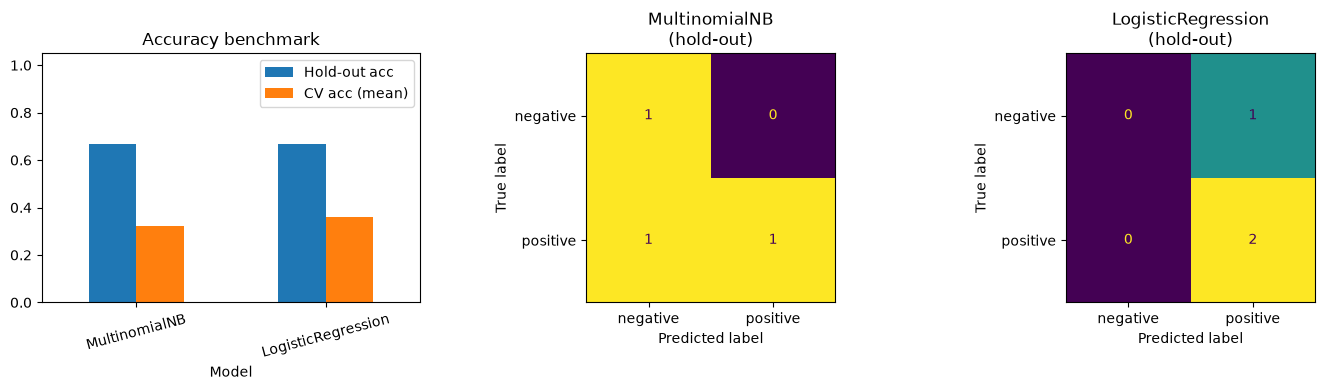

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
benchmark[["Hold-out acc", "CV acc (mean)"]].plot.bar(ax=axes[0], ylim=(0, 1.05), rot=15, title="Accuracy benchmark")
for ax, (name, pipe) in zip(axes[1:], fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pipe.predict(X_te), labels=[0, 1]),
                           display_labels=["negative", "positive"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name}\n(hold-out)")
plt.tight_layout(); plt.show()

## 6. Most influential words

In [9]:
final = {n: f().fit(X, y) for n, f in models.items()}     # refit on ALL data for deployment

def top_words(pipe, k=8):
    vocab = np.array(pipe.named_steps["tfidf"].get_feature_names_out())
    clf = pipe.named_steps["clf"]
    score = clf.coef_[0] if hasattr(clf, "coef_") and clf.coef_.shape[0] == 1 and not isinstance(clf, MultinomialNB) \
            else clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
    order = np.argsort(score)
    return list(vocab[order[-k:]][::-1]), list(vocab[order[:k]])

for name, pipe in final.items():
    pos, neg = top_words(pipe)
    print(f"{name}\n  positive: {pos}\n  negative: {neg}\n")

MultinomialNB
  positive: ['setup', 'quality exceptional', 'quality', 'product', 'product quality', 'expectation', 'exceptional', 'exceptional exceed']
  negative: ['disappoint purchase', 'disappoint', 'day extremely', 'day', 'extremely disappoint', 'extremely', 'stop work', 'stop']

LogisticRegression
  positive: ['setup', 'quality exceptional', 'quality', 'product', 'product quality', 'expectation', 'exceptional', 'exceptional exceed']
  negative: ['disappoint purchase', 'disappoint', 'day extremely', 'day', 'extremely disappoint', 'extremely', 'stop work', 'stop']



## 7. `predict_sentiment()` and interactive test helper

`predict_sentiment(text)` returns the label and confidence for any phrase. Run `interactive_test()` to type your own reviews live (type `quit` to stop).

In [10]:
def predict_sentiment(text: str, model: str = "LogisticRegression", verbose: bool = True) -> dict:
    """Predict 'positive'/'negative' for raw text using a model trained on the full dataset."""
    pipe = final[model]
    cleaned = clean_text(text)
    if not cleaned:
        out = {"text": text, "model": model, "label": "unknown", "confidence": 0.0}
    else:
        proba = pipe.predict_proba([cleaned])[0]
        idx = int(np.argmax(proba))
        out = {"text": text, "model": model,
               "label": "positive" if idx == 1 else "negative",
               "confidence": round(float(proba[idx]), 3)}
    if verbose:
        print(f"[{out['model']}] {out['label'].upper():8s} ({out['confidence']:.0%})  <-  {text}")
    return out

tests = [
    "I absolutely love this, works perfectly and great value!",
    "Terrible quality, it broke after two days. Very disappointed.",
    "Not worth the money.",
    "Fast delivery and helpful support, highly recommended.",
]
for t in tests:
    for m in final:
        predict_sentiment(t, m)
    print()

[MultinomialNB] POSITIVE (68%)  <-  I absolutely love this, works perfectly and great value!
[LogisticRegression] POSITIVE (78%)  <-  I absolutely love this, works perfectly and great value!

[MultinomialNB] NEGATIVE (52%)  <-  Terrible quality, it broke after two days. Very disappointed.
[LogisticRegression] NEGATIVE (58%)  <-  Terrible quality, it broke after two days. Very disappointed.

[MultinomialNB] NEGATIVE (60%)  <-  Not worth the money.
[LogisticRegression] NEGATIVE (69%)  <-  Not worth the money.

[MultinomialNB] POSITIVE (62%)  <-  Fast delivery and helpful support, highly recommended.
[LogisticRegression] POSITIVE (68%)  <-  Fast delivery and helpful support, highly recommended.



In [11]:
def interactive_test(model="LogisticRegression"):
    """Type reviews and get live predictions. Enter 'quit' to exit."""
    print(f"Interactive sentiment tester ({model}). Type 'quit' to exit.")
    while True:
        text = input("Review > ").strip()
        if text.lower() in {"quit", "exit", "q", ""}:
            print("Bye!"); break
        predict_sentiment(text, model)

# Uncomment to run:
# interactive_test()

In [12]:
# Optional: save the trained model for reuse in other scripts
import joblib
joblib.dump(final["LogisticRegression"], "sentiment_model.joblib")
print("Saved sentiment_model.joblib")

Saved sentiment_model.joblib


## 8. Notes & limitations

- **Tiny dataset:** with ~9 labeled reviews, cross-validation accuracy can land at or even below chance (each fold's training set is only 6 reviews and often contains none of the words in the held-out reviews). That reflects the data size, not a bug in the pipeline. The metrics have high variance and the models only know words seen in training. For a production-grade classifier, train on thousands of reviews (IMDB 50k, Amazon reviews, etc.) by changing `DATA_PATH`.
- **Neutral class** was excluded to match the binary task; it could be added by setting `KEEP_LABELS` to all three labels (`label` encoding would then need to be multi-class).
- **Naive Bayes vs Logistic Regression:** NB is fast and strong on small text sets; LR typically wins as data grows because it weighs correlated features properly.